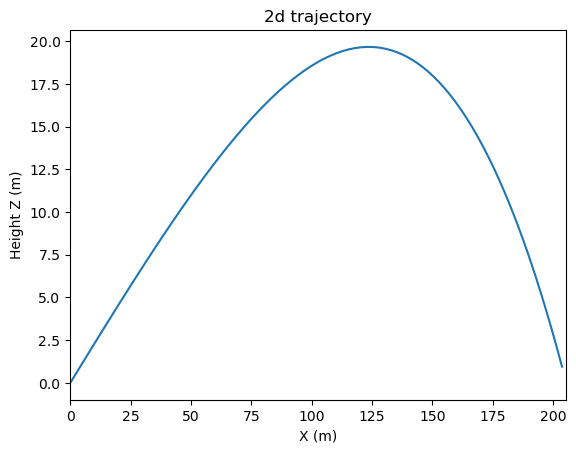

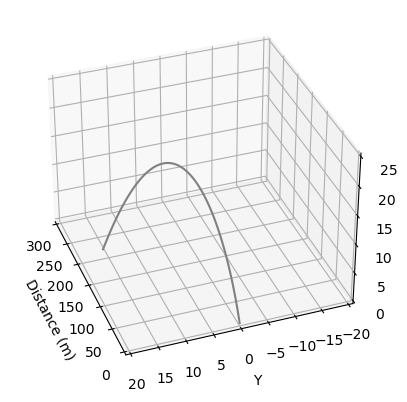

In [1]:
import os
import numpy as np
import math

from scipy.integrate import odeint,RK45

import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d

## Constants
## ===========================================================

m     = 0.045
A     = 0.0014129
rho   = 1.177
omega = np.array([100,-200,100])
d     = 0.00042
g     = 9.8
mu    = 1.846*10e-5


## Initial values
## ===========================================================

## Position
x0 = np.zeros(6);

## Intial velocity (m/s)
u0    = 71.52

## Initial angle (rad/s)
alpha0 = 13 * math.pi/180

## Initial vector velocity
x0[3] = u0 *math.cos(alpha0)
x0[5] = u0 *math.sin(alpha0)

## Initial Spin paramater
s0   = (np.linalg.norm(omega)*d)
Cmag = s0
## Reynolds number (for drag)
Re    = rho*u0*d/mu
Cd = 0.22;

## Phisic Model
## ===========================================================

## Magnus Effect
def FMagnus(dx,rho,A,Cmag,omega):

	return ((0.5*rho*A*Cmag*np.linalg.norm(dx)**2)/np.linalg.norm(np.cross(omega,dx)))*np.cross(omega,dx)

## Drag
def FDrag(dx,rho,A,Cd):

	return -0.5*rho*A*Cd*np.linalg.norm(dx)*dx

## Gravity
def FGravity(m,g):

	Fg = np.zeros(3)
	Fg[2] = -m*g
	return Fg

## Ball Equations
def ball_dynamics(x,t,rho,A,Cmag,omega,Cd,m,g):


	# Velocity vector
	dx = x[3:6]

	Fm = FMagnus(dx,rho,A,Cmag,omega)
	Fd = FDrag(dx,rho,A,Cd)
	Fg = FGravity(m,g)

	F = np.zeros(6)
	F[0:3] = x[3:6]
	F[3:6] = (Fm+Fd+Fg)/m

	return F

## ODE solver
## ===========================================================

## time points
n  = 100
tf = 6
t  = np.linspace(0,tf,n)


## Solve ODE
x = odeint(ball_dynamics,x0,t,args=(rho,A,Cmag,omega,Cd,m,g,))

## Post analysis
## ===========================================================

## Landing point
touch_down = np.where([x[:,2] < 0])[1][0]

distance     = x[touch_down,0]
max_altitude = np.amax(x[:touch_down,2])
flight_time  = t[touch_down]


## Plots
## ===========================================================

## X-Z plot
fig1 = plt.figure(1)
plt.plot(x[:touch_down,0],x[:touch_down,2])
plt.title('2d trajectory')
plt.xlabel("X (m)")
plt.ylabel("Height Z (m)")
plt.xlim(x[0,0], x[touch_down,0])


## 3d plot
fig2 = plt.figure(2)
ax = plt.axes(projection='3d')
ax.plot3D(x[:touch_down,0],x[:touch_down,1],x[:touch_down,2], 'gray')
ax.set_xlim(0, 300)
ax.set_ylim(-20, 20)
ax.set_zlim(0, 25)
ax.set_xlabel('Distance (m)')
ax.set_ylabel('Y')
ax.set_zlabel('Height (m)')
ax.view_init(azim=160,elev=34)

plt.show()